# ANN Hyperparameter Study
Using the same data preparation as `01_ann_baseline.ipynb`, the effect of the following on the model performance is studied:
1. Number of hidden layers
2. Number of hidden nodes
3. Activation function
4. Number of epochs
5. Training sample size

**How the comparison is done**
- Every configuration is trained with **3 different random seeds** and the mean ± standard deviation of R² is reported, because a single run can be better or worse just by chance.
- The configurations are compared on the **validation data**. The test data is used only once at the end, for the finally selected configuration, so that the test score is an honest estimate on unseen data.

## Importing Libraries and Preparing the Data

In [8]:
import pandas as pa
import numpy as np
import matplotlib.pyplot as mplt
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error,r2_score
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import random
import logging
logging.getLogger('tensorflow').setLevel(logging.ERROR)

np.random.seed(50)
tf.random.set_seed(50)
random.seed(50)

# Reading the dataset
data=pa.read_excel("../data/nanofluid_dataset.xlsx")


data.columns=[col.replace('Â','') for col in data.columns]
target='Heat_Transfer_Coefficient (W/m²K)'
A=data.drop(columns=[target])            #Inputs
B=data[target]                           #Output

#One-Hot Encoding both the Nanoparticle_Type and Base_Fluid as they are categorical variables with no order
cat_cols=['Nanoparticle_Type','Base_Fluid']
A=pa.get_dummies(A,columns=cat_cols,dtype=float)

#Splitting into train,validation and test in 70:15:15 (before normalization)
A_train,A_temp,B_train,B_temp=train_test_split(A,B,test_size=0.30,random_state=7)
A_val,A_test,B_val,B_test=train_test_split(A_temp,B_temp,test_size=0.50,random_state=7)

#Normalizing the numerical input features between 0 and 1
num_cols=['Volume_Fraction (%)','Temperature (°C)','Flow_Velocity (m/s)','Thermal_Conductivity (W/mK)',
          'Specific_Heat_Capacity (J/kgK)','Density (kg/m³)','Viscosity (Pa·s)']
scaler=MinMaxScaler()
A_train[num_cols]=scaler.fit_transform(A_train[num_cols])
A_val[num_cols]=scaler.transform(A_val[num_cols])
A_test[num_cols]=scaler.transform(A_test[num_cols])

#Scaler for the output (fitted only on the training output)
scaler_B=MinMaxScaler()
scaler_B.fit(B_train.values.reshape(-1,1))

print("Training Set Size:",A_train.shape)
print("Validation Set Size:",A_val.shape)
print("Testing Set Size:",A_test.shape)

Training Set Size: (7205, 16)
Validation Set Size: (1544, 16)
Testing Set Size: (1544, 16)


## Function for the Analysis

In [9]:
seeds = [0, 1, 2]    
results = []         

def perform_analysis(A_train_data, B_train_data, A_eval_data, B_eval_data, 
                     hidden_layers, activation_function, epochs, eval_name='Validation'):

    # Scaling the training output between 0 and 1 using the scaler fitted on the training data
    B_train_scaled = scaler_B.transform(B_train_data.values.reshape(-1,1))
    
    input_nodes = A_train_data.shape[1]
    r2_train_list = []
    r2_eval_list = []
    
    for seed in seeds:
        keras.utils.set_random_seed(seed)
        
        # Build the model dynamically based on the 'hidden_layers' list
        model = keras.Sequential()
        model.add(keras.Input(shape=(input_nodes,)))
        
        for nodes in hidden_layers:
            model.add(layers.Dense(nodes, activation=activation_function))
        
        model.add(layers.Dense(1, activation='linear'))
    
        model.compile(optimizer='adam', loss='mean_squared_error')
        history = model.fit(A_train_data, B_train_scaled, epochs=epochs, verbose=0)
        
        # Predict and convert the predictions back to the original units (W/m²K)
        B_train_pred = scaler_B.inverse_transform(model.predict(A_train_data, verbose=0))
        B_eval_pred = scaler_B.inverse_transform(model.predict(A_eval_data, verbose=0))
        
        r2_train_list.append(r2_score(B_train_data, B_train_pred))
        r2_eval_list.append(r2_score(B_eval_data, B_eval_pred))
    
    print(f"\n Analysis Results (mean ± std over {len(seeds)} seeds) ")
    print(f"Layers: {len(hidden_layers)} | Nodes: {hidden_layers} | Activation: {activation_function} | Epochs: {epochs} | Training samples: {len(A_train_data)}")
    print(f"Training R^2: {np.mean(r2_train_list):.4f} ± {np.std(r2_train_list):.4f} | {eval_name} R^2: {np.mean(r2_eval_list):.4f} ± {np.std(r2_eval_list):.4f}")
    
    results.append({'Nodes': str(hidden_layers), 'Activation': activation_function, 'Epochs': epochs,
                    'Training samples': len(A_train_data), 'Evaluated on': eval_name,
                    'Train R2 (mean)': np.mean(r2_train_list), 'Train R2 (std)': np.std(r2_train_list),
                    'Eval R2 (mean)': np.mean(r2_eval_list), 'Eval R2 (std)': np.std(r2_eval_list)})
    
    # Plotting True vs. Predicted (for the last seed)
    fig, (ax1, ax2) = mplt.subplots(1, 2, figsize=(14, 6))

    # Training Data Plot
    ax1.scatter(B_train_data, B_train_pred, alpha=0.5)
    ax1.plot([B_train_data.min(), B_train_data.max()],
             [B_train_data.min(), B_train_data.max()], 'r--', lw=2)
    ax1.set_title('Training Data: True vs. Predicted')
    ax1.set_xlabel('True Values')
    ax1.set_ylabel('Predicted Values')

    # Validation/Testing Data Plot
    ax2.scatter(B_eval_data, B_eval_pred, alpha=0.5)
    ax2.plot([B_eval_data.min(), B_eval_data.max()],
             [B_eval_data.min(), B_eval_data.max()], 'r--', lw=2)
    ax2.set_title(f'{eval_name} Data: True vs. Predicted')
    ax2.set_xlabel('True Values')
    ax2.set_ylabel('Predicted Values')
    
    mplt.tight_layout()
    mplt.show()
    
    return np.ravel(B_eval_pred)

## Varying the Number Of Hidden Layers



 Analysis 1A: Hidden Layers = 1

 Analysis Results (mean ± std over 3 seeds) 
Layers: 1 | Nodes: [64] | Activation: relu | Epochs: 150 | Training samples: 7205
Training R^2: 0.9928 ± 0.0013 | Validation R^2: 0.9903 ± 0.0019


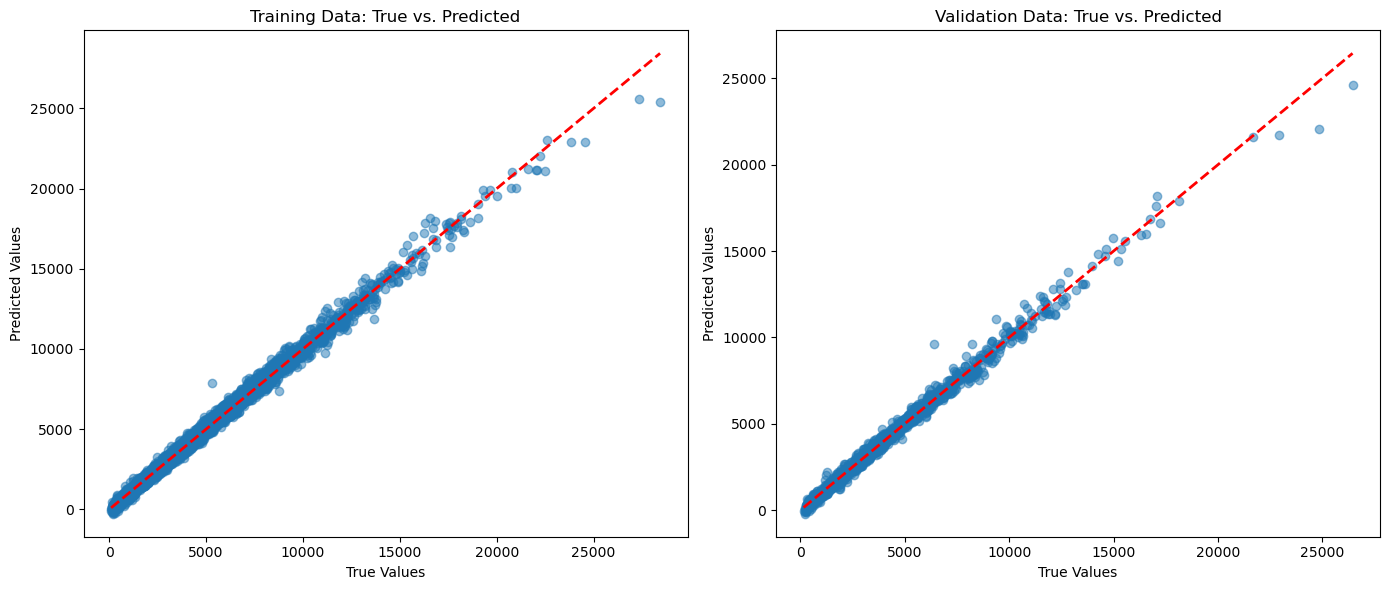



 Analysis 1B: Hidden Layers = 2

 Analysis Results (mean ± std over 3 seeds) 
Layers: 2 | Nodes: [64, 32] | Activation: relu | Epochs: 150 | Training samples: 7205
Training R^2: 0.9950 ± 0.0008 | Validation R^2: 0.9910 ± 0.0005


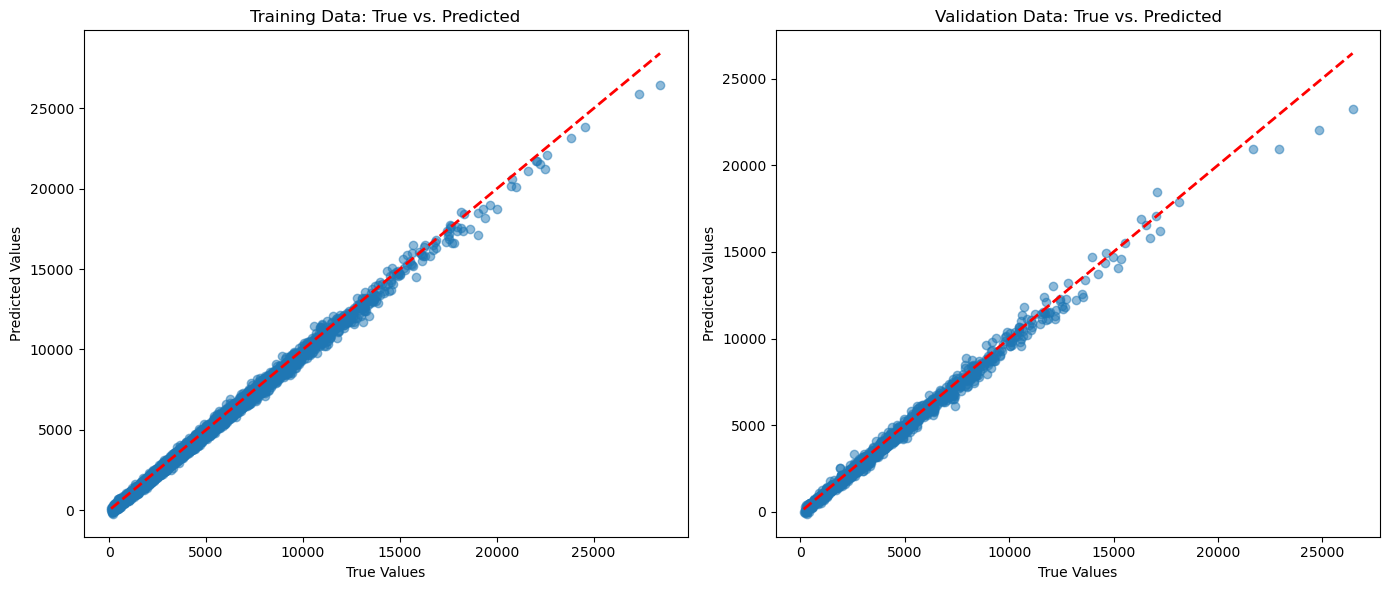



 Analysis 1C: Hidden Layers = 3

 Analysis Results (mean ± std over 3 seeds) 
Layers: 3 | Nodes: [64, 32, 16] | Activation: relu | Epochs: 150 | Training samples: 7205
Training R^2: 0.9952 ± 0.0007 | Validation R^2: 0.9906 ± 0.0008


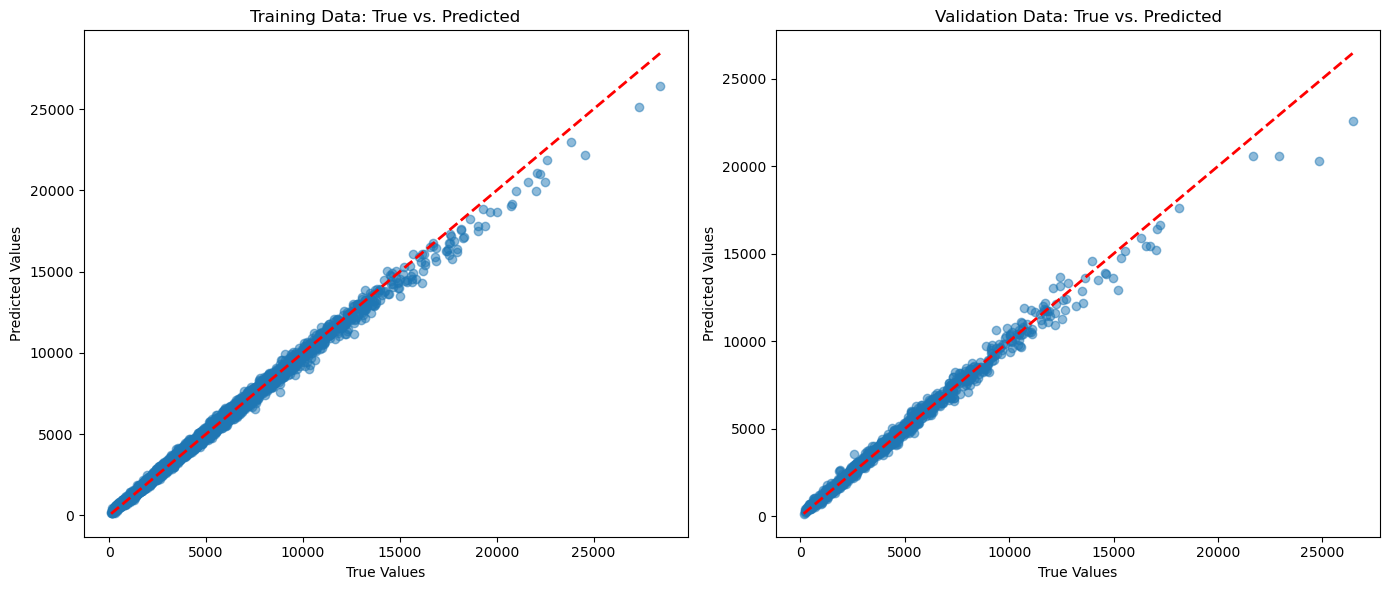

In [10]:
print("\n\n Analysis 1A: Hidden Layers = 1")
HL1 = perform_analysis(A_train, B_train, A_val, B_val,
                       hidden_layers=[64],
                       activation_function='relu', epochs=150)

print("\n\n Analysis 1B: Hidden Layers = 2")
HL2 = perform_analysis(A_train, B_train, A_val, B_val,
                       hidden_layers=[64, 32],
                       activation_function='relu', epochs=150)

print("\n\n Analysis 1C: Hidden Layers = 3")
HL3 = perform_analysis(A_train, B_train, A_val, B_val,
                       hidden_layers=[64, 32, 16],
                       activation_function='relu', epochs=150)

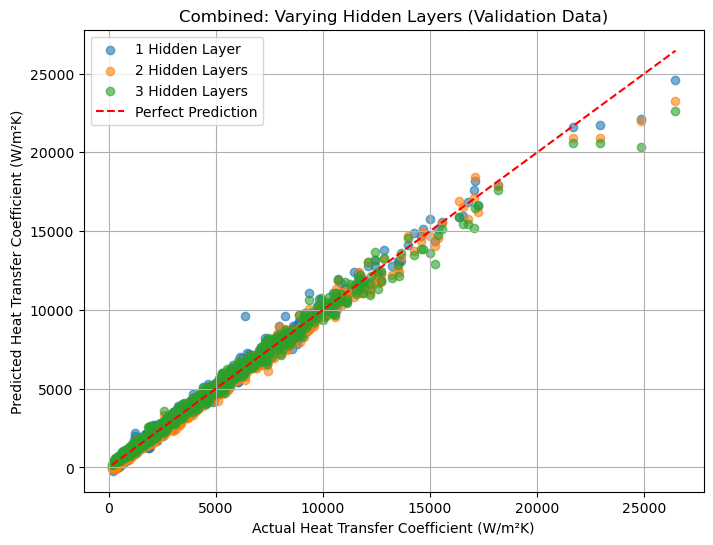

In [11]:
#Plotting all the Varying Hidden Layers of Validation Data

mplt.figure(figsize=(8,6))
mplt.scatter(B_val, HL1, alpha=0.6, label='1 Hidden Layer')
mplt.scatter(B_val, HL2, alpha=0.6, label='2 Hidden Layers')
mplt.scatter(B_val, HL3, alpha=0.6, label='3 Hidden Layers')

mplt.plot([B_val.min(), B_val.max()],
          [B_val.min(), B_val.max()],
          'r--', label="Perfect Prediction")

mplt.xlabel("Actual Heat Transfer Coefficient (W/m²K)")
mplt.ylabel("Predicted Heat Transfer Coefficient (W/m²K)")
mplt.title("Combined: Varying Hidden Layers (Validation Data)")
mplt.legend()
mplt.grid(True)
mplt.show()

## Varying the Hidden Nodes



 Analysis 2A: Nodes = [16, 8] 

 Analysis Results (mean ± std over 3 seeds) 
Layers: 2 | Nodes: [16, 8] | Activation: relu | Epochs: 150 | Training samples: 7205
Training R^2: 0.9888 ± 0.0020 | Validation R^2: 0.9860 ± 0.0019


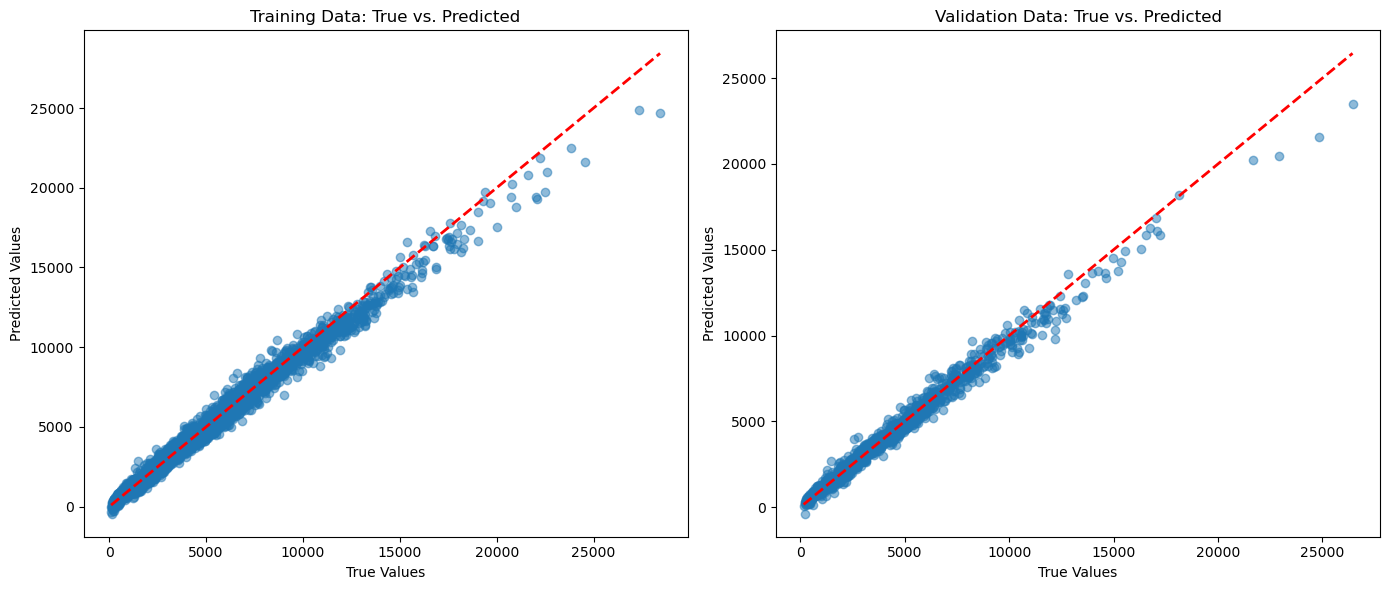



 Analysis 2B: Nodes = [64, 32] 

 Analysis Results (mean ± std over 3 seeds) 
Layers: 2 | Nodes: [64, 32] | Activation: relu | Epochs: 150 | Training samples: 7205
Training R^2: 0.9950 ± 0.0008 | Validation R^2: 0.9910 ± 0.0005


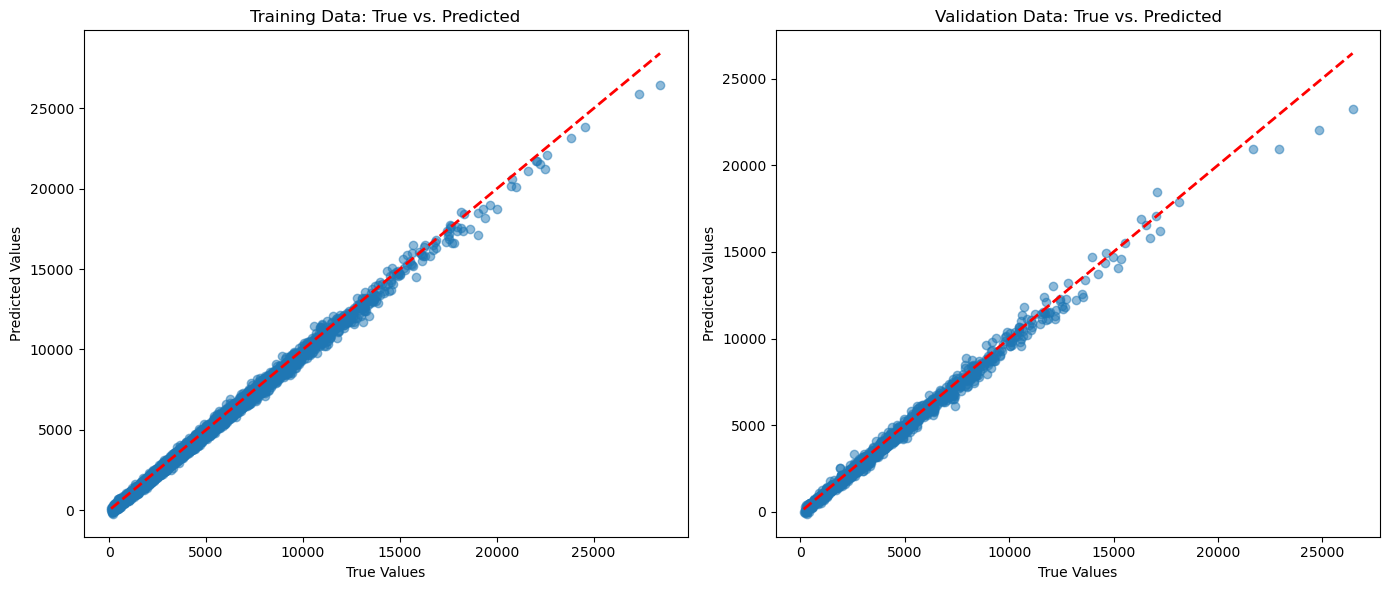



 Analysis 2C: Nodes = [128, 64] 

 Analysis Results (mean ± std over 3 seeds) 
Layers: 2 | Nodes: [128, 64] | Activation: relu | Epochs: 150 | Training samples: 7205
Training R^2: 0.9947 ± 0.0018 | Validation R^2: 0.9899 ± 0.0016


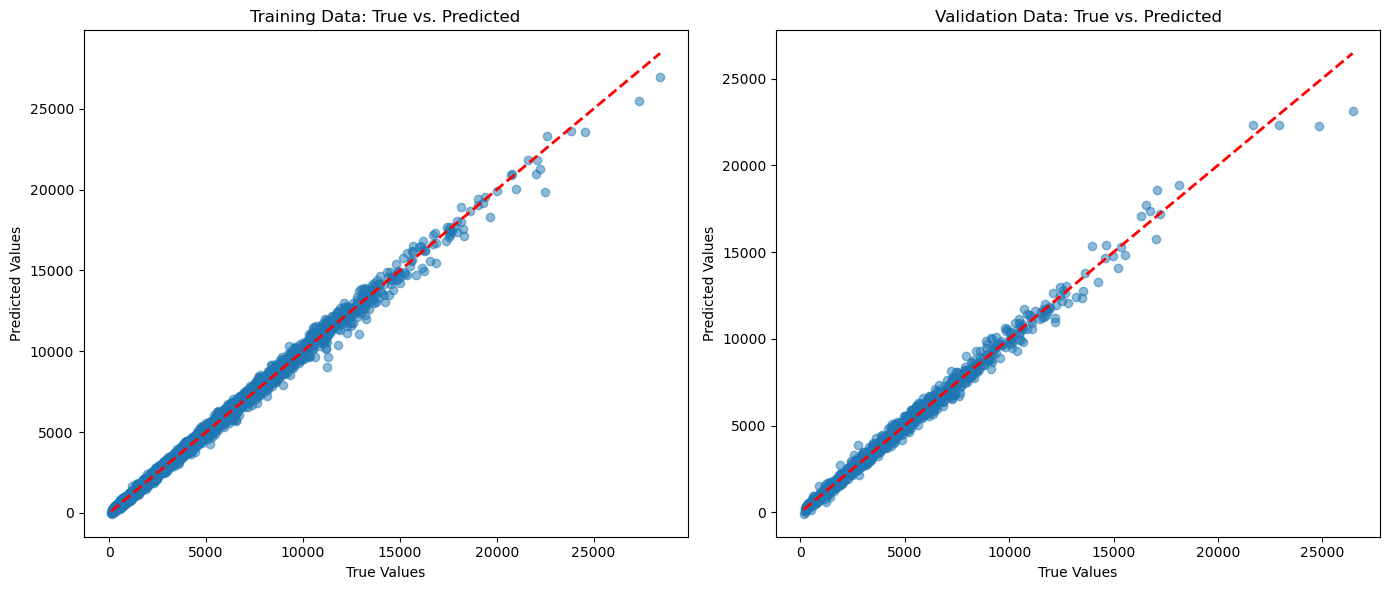

In [12]:
print("\n\n Analysis 2A: Nodes = [16, 8] ")
HN1 = perform_analysis(A_train, B_train, A_val, B_val,
                       hidden_layers=[16, 8],
                       activation_function='relu', epochs=150)

print("\n\n Analysis 2B: Nodes = [64, 32] ")
HN2 = perform_analysis(A_train, B_train, A_val, B_val,
                       hidden_layers=[64, 32],
                       activation_function='relu', epochs=150)

print("\n\n Analysis 2C: Nodes = [128, 64] ")
HN3 = perform_analysis(A_train, B_train, A_val, B_val,
                       hidden_layers=[128, 64],
                       activation_function='relu', epochs=150)

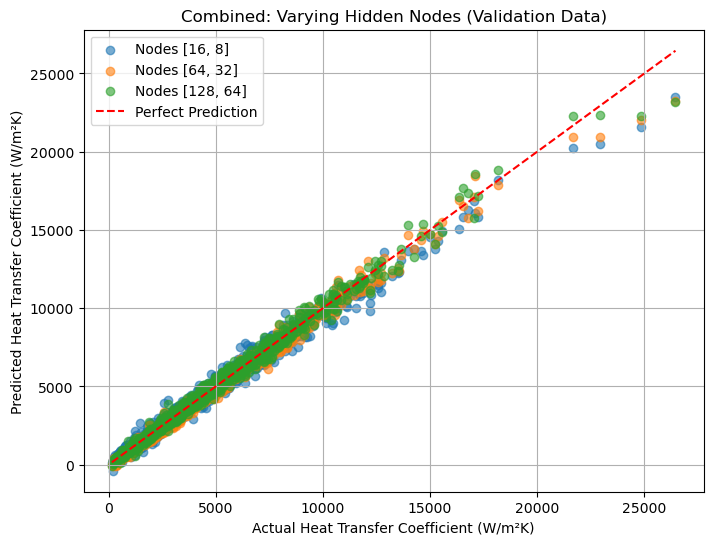

In [13]:
#Combined Plot for Hidden Nodes

mplt.figure(figsize=(8,6))
mplt.scatter(B_val, HN1, alpha=0.6, label='Nodes [16, 8]')
mplt.scatter(B_val, HN2, alpha=0.6, label='Nodes [64, 32]')
mplt.scatter(B_val, HN3, alpha=0.6, label='Nodes [128, 64]')

mplt.plot([B_val.min(), B_val.max()],
          [B_val.min(), B_val.max()],
          'r--', label="Perfect Prediction")

mplt.xlabel("Actual Heat Transfer Coefficient (W/m²K)")
mplt.ylabel("Predicted Heat Transfer Coefficient (W/m²K)")
mplt.title("Combined: Varying Hidden Nodes (Validation Data)")
mplt.legend()
mplt.grid(True)
mplt.show()

## Varying Activation Functions



 Analysis 3A: Activation = tanh 

 Analysis Results (mean ± std over 3 seeds) 
Layers: 2 | Nodes: [64, 32] | Activation: tanh | Epochs: 150 | Training samples: 7205
Training R^2: 0.9947 ± 0.0004 | Validation R^2: 0.9936 ± 0.0002


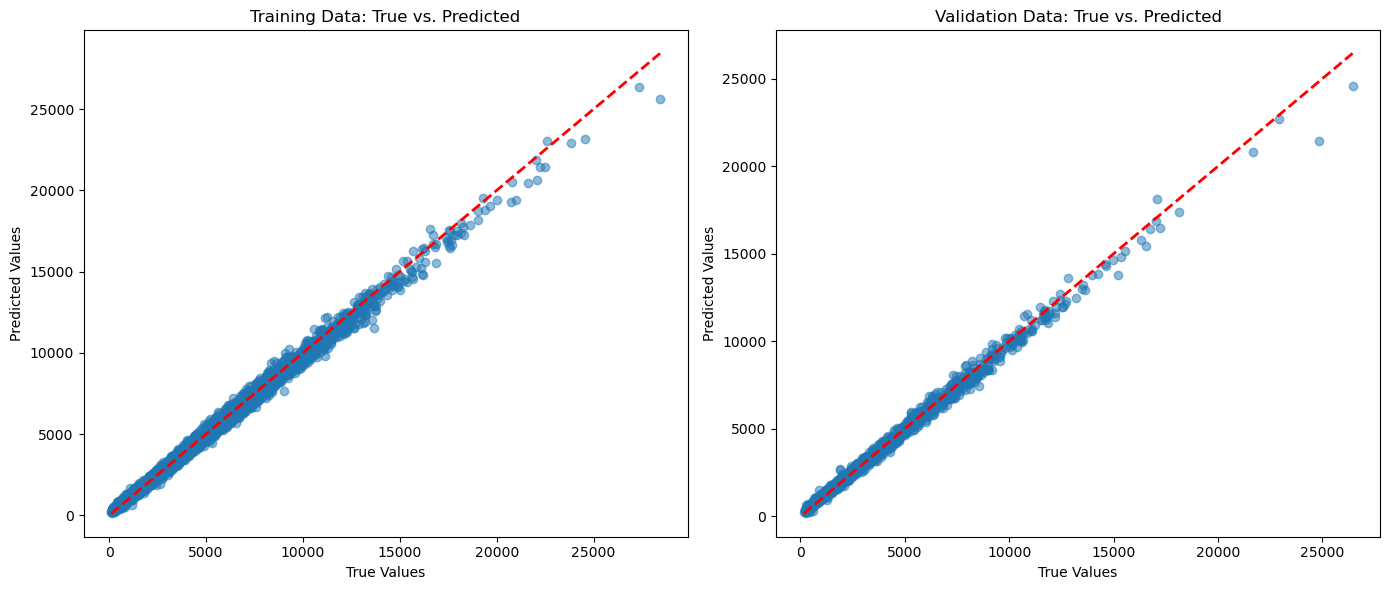



 Analysis 3B: Activation = relu 

 Analysis Results (mean ± std over 3 seeds) 
Layers: 2 | Nodes: [64, 32] | Activation: relu | Epochs: 150 | Training samples: 7205
Training R^2: 0.9950 ± 0.0008 | Validation R^2: 0.9910 ± 0.0005


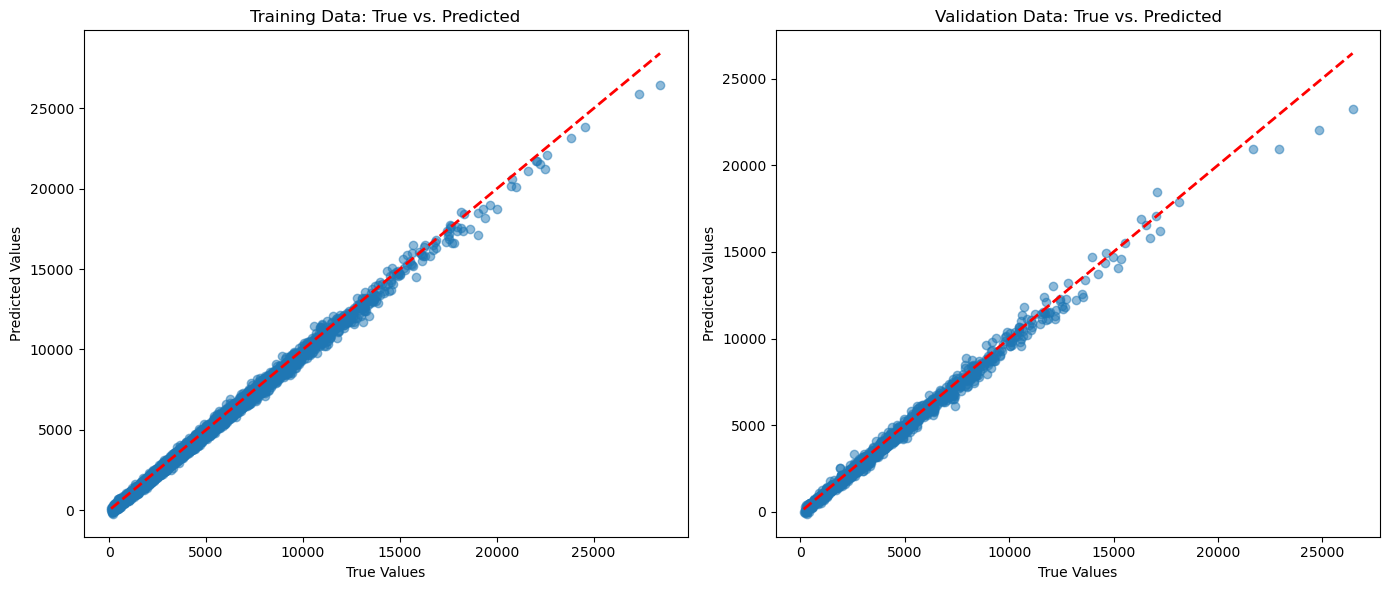



 Analysis 3C: Activation = sigmoid 

 Analysis Results (mean ± std over 3 seeds) 
Layers: 2 | Nodes: [64, 32] | Activation: sigmoid | Epochs: 150 | Training samples: 7205
Training R^2: 0.9885 ± 0.0048 | Validation R^2: 0.9878 ± 0.0048


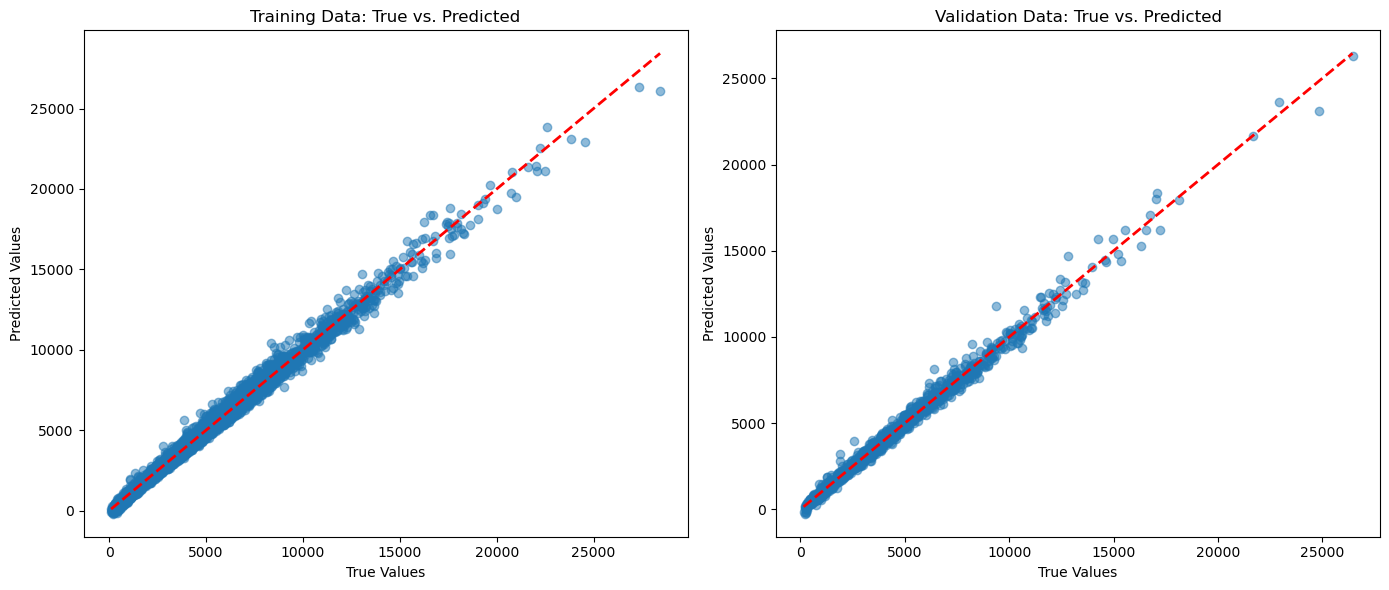

In [14]:
print("\n\n Analysis 3A: Activation = tanh ")
AF_tanh = perform_analysis(A_train, B_train, A_val, B_val,
                       hidden_layers=[64, 32],
                       activation_function='tanh', epochs=150)

print("\n\n Analysis 3B: Activation = relu ")
AF_relu = perform_analysis(A_train, B_train, A_val, B_val,
                       hidden_layers=[64, 32],
                       activation_function='relu', epochs=150)

print("\n\n Analysis 3C: Activation = sigmoid ")
AF_sigmoid = perform_analysis(A_train, B_train, A_val, B_val,
                       hidden_layers=[64, 32],
                       activation_function='sigmoid', epochs=150)

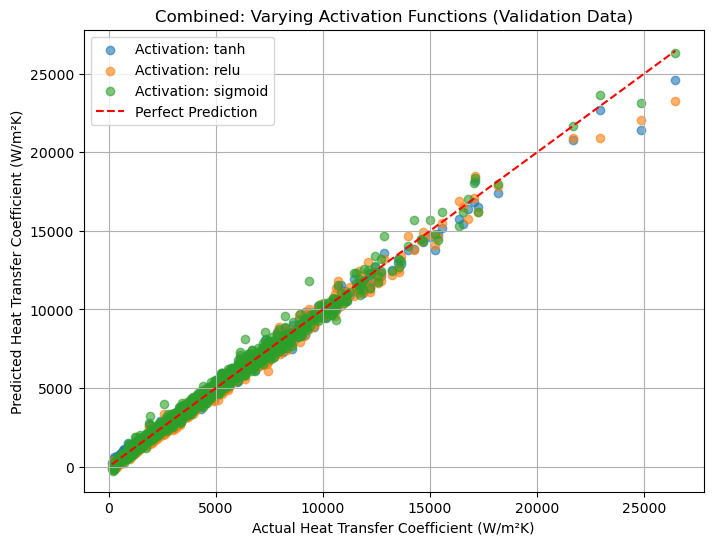

In [15]:
#Combined plot for all the activation functions

mplt.figure(figsize=(8,6))
mplt.scatter(B_val, AF_tanh, alpha=0.6, label='Activation: tanh')
mplt.scatter(B_val, AF_relu, alpha=0.6, label='Activation: relu')
mplt.scatter(B_val, AF_sigmoid, alpha=0.6, label='Activation: sigmoid')

mplt.plot([B_val.min(), B_val.max()],
          [B_val.min(), B_val.max()],
          'r--', label="Perfect Prediction")

mplt.xlabel("Actual Heat Transfer Coefficient (W/m²K)")
mplt.ylabel("Predicted Heat Transfer Coefficient (W/m²K)")
mplt.title("Combined: Varying Activation Functions (Validation Data)")
mplt.legend()
mplt.grid(True)
mplt.show()

## Varying the Number of Epochs



 Analysis 4A: Epochs = 50 

 Analysis Results (mean ± std over 3 seeds) 
Layers: 2 | Nodes: [64, 32] | Activation: relu | Epochs: 50 | Training samples: 7205
Training R^2: 0.9917 ± 0.0019 | Validation R^2: 0.9872 ± 0.0020


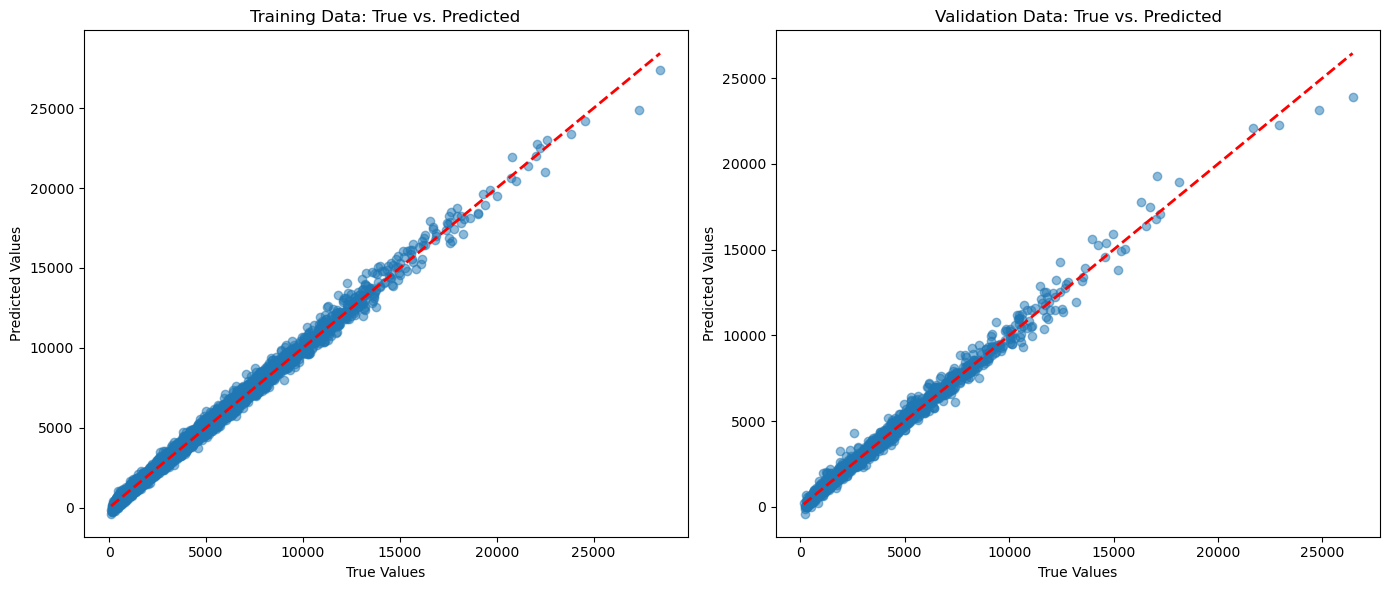



 Analysis 4B: Epochs = 150 

 Analysis Results (mean ± std over 3 seeds) 
Layers: 2 | Nodes: [64, 32] | Activation: relu | Epochs: 150 | Training samples: 7205
Training R^2: 0.9950 ± 0.0008 | Validation R^2: 0.9910 ± 0.0005


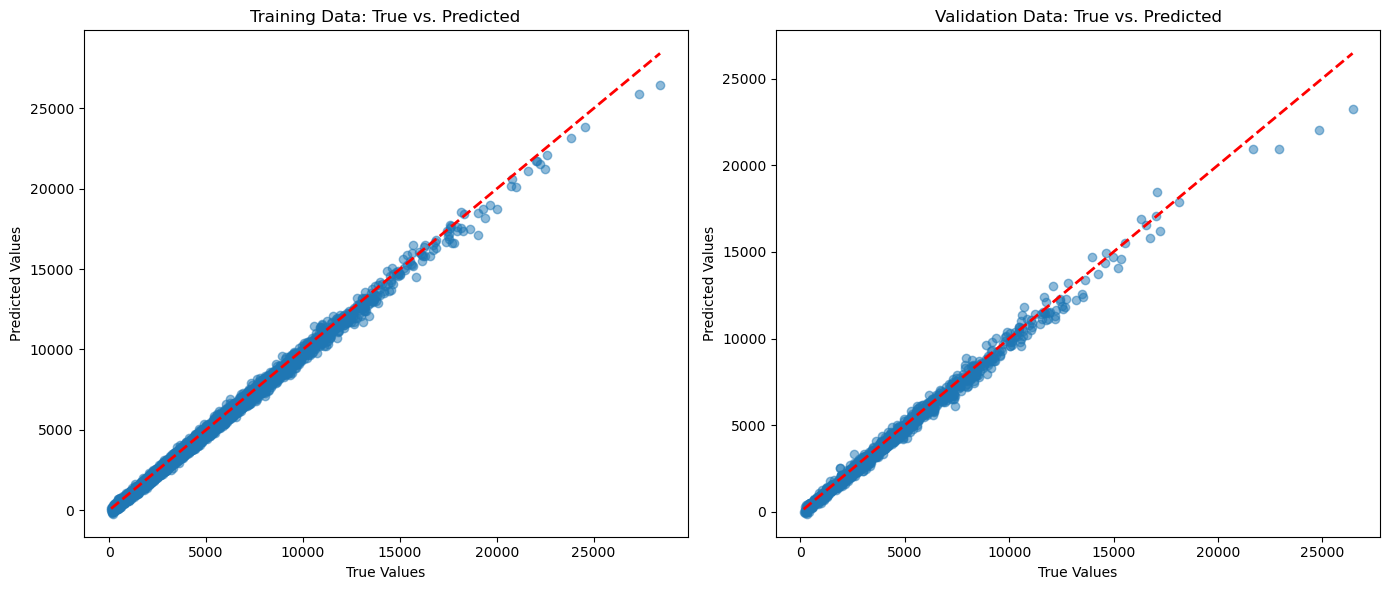



 Analysis 4C: Epochs = 250 

 Analysis Results (mean ± std over 3 seeds) 
Layers: 2 | Nodes: [64, 32] | Activation: relu | Epochs: 250 | Training samples: 7205
Training R^2: 0.9972 ± 0.0004 | Validation R^2: 0.9929 ± 0.0006


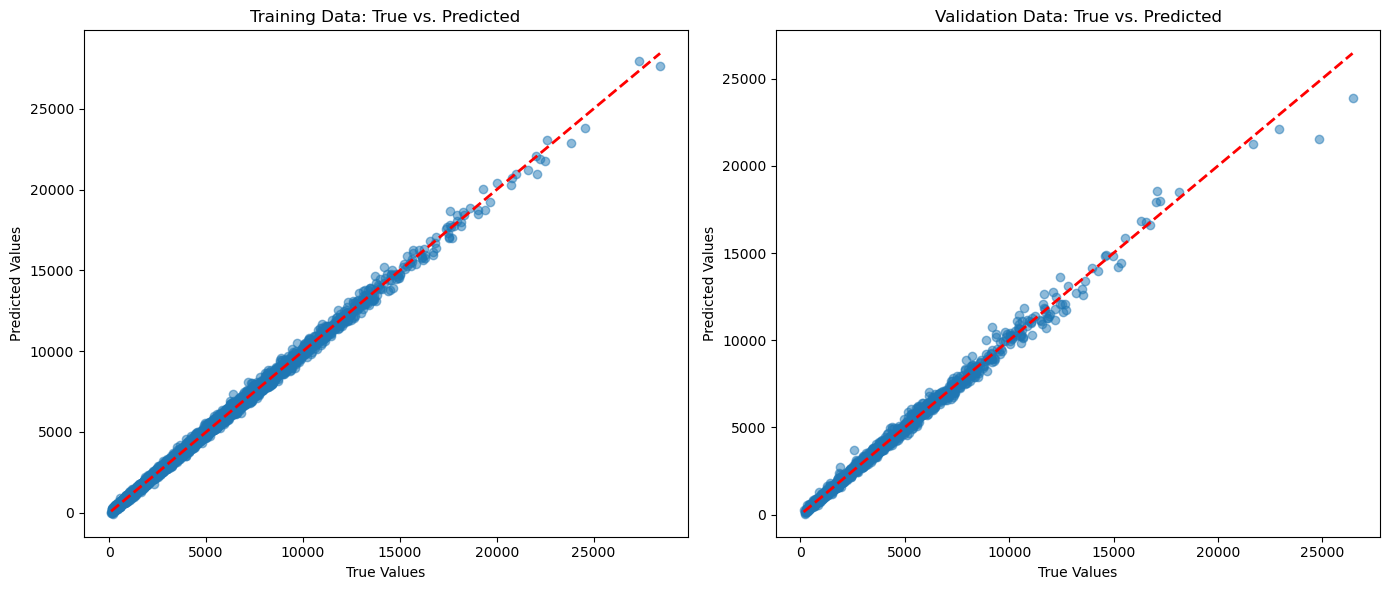

In [16]:
print("\n\n Analysis 4A: Epochs = 50 ")
EP50 = perform_analysis(A_train, B_train, A_val, B_val,
                       hidden_layers=[64, 32],
                       activation_function='relu', epochs=50)

print("\n\n Analysis 4B: Epochs = 150 ")
EP150 = perform_analysis(A_train, B_train, A_val, B_val,
                       hidden_layers=[64, 32],
                       activation_function='relu', epochs=150)

print("\n\n Analysis 4C: Epochs = 250 ")
EP250 = perform_analysis(A_train, B_train, A_val, B_val,
                       hidden_layers=[64, 32],
                       activation_function='relu', epochs=250)

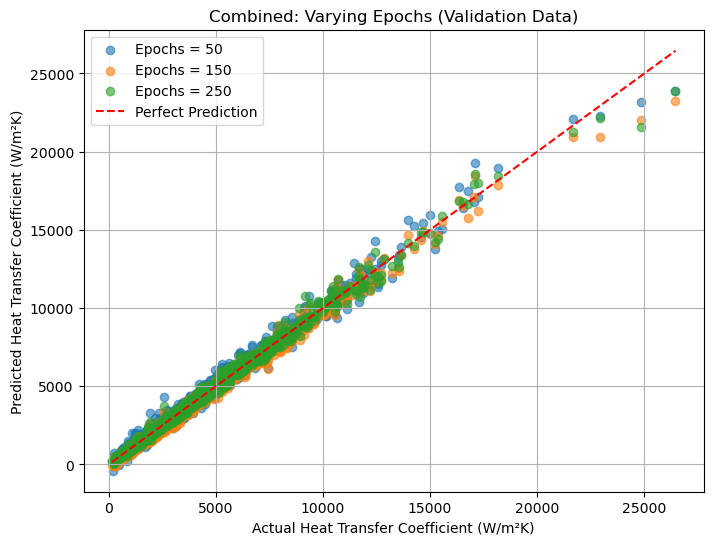

In [17]:
#Combined plot for all the epochs

mplt.figure(figsize=(8,6))
mplt.scatter(B_val, EP50, alpha=0.6, label='Epochs = 50')
mplt.scatter(B_val, EP150, alpha=0.6, label='Epochs = 150')
mplt.scatter(B_val, EP250, alpha=0.6, label='Epochs = 250')

mplt.plot([B_val.min(), B_val.max()],
          [B_val.min(), B_val.max()],
          'r--', label="Perfect Prediction")

mplt.xlabel("Actual Heat Transfer Coefficient (W/m²K)")
mplt.ylabel("Predicted Heat Transfer Coefficient (W/m²K)")
mplt.title("Combined: Varying Epochs (Validation Data)")
mplt.legend()
mplt.grid(True)
mplt.show()

## Varying Sample Size for Training Data

Small Training Sample : 2882
Medium Training Sample: 5043
Full Training Sample  : 7205

Small Training Sample 

 Analysis Results (mean ± std over 3 seeds) 
Layers: 2 | Nodes: [64, 32] | Activation: relu | Epochs: 150 | Training samples: 2882
Training R^2: 0.9929 ± 0.0032 | Validation R^2: 0.9801 ± 0.0054


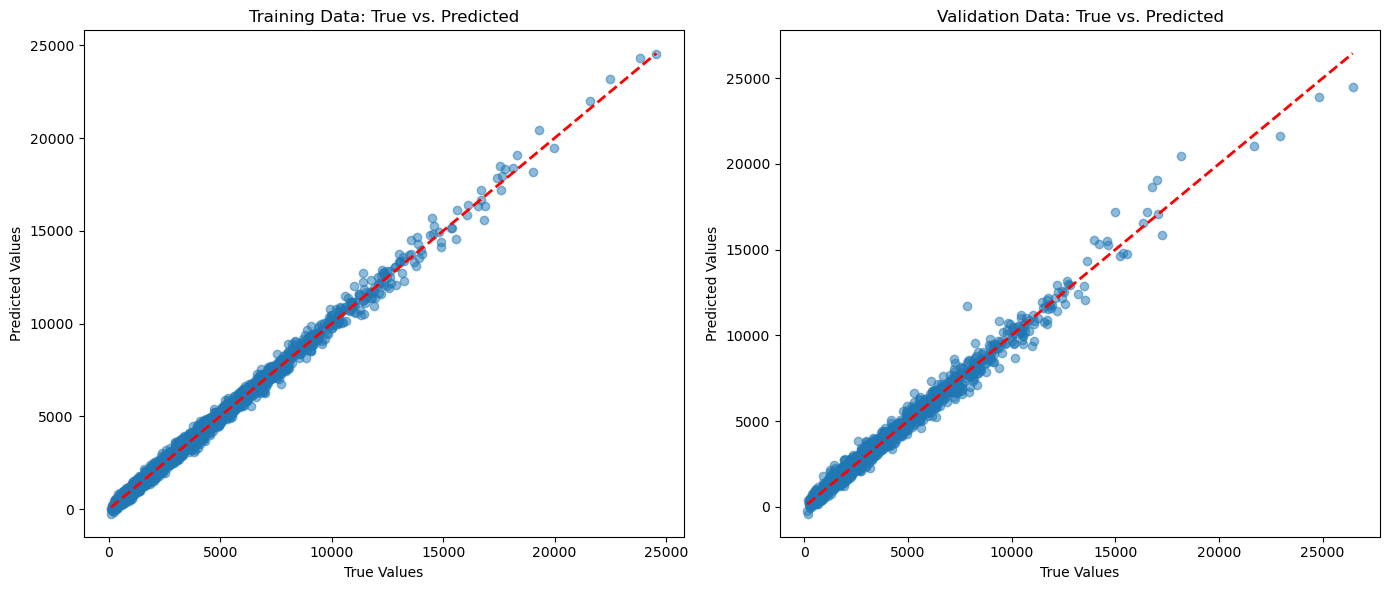


 Medium Training Sample 

 Analysis Results (mean ± std over 3 seeds) 
Layers: 2 | Nodes: [64, 32] | Activation: relu | Epochs: 150 | Training samples: 5043
Training R^2: 0.9935 ± 0.0011 | Validation R^2: 0.9862 ± 0.0035


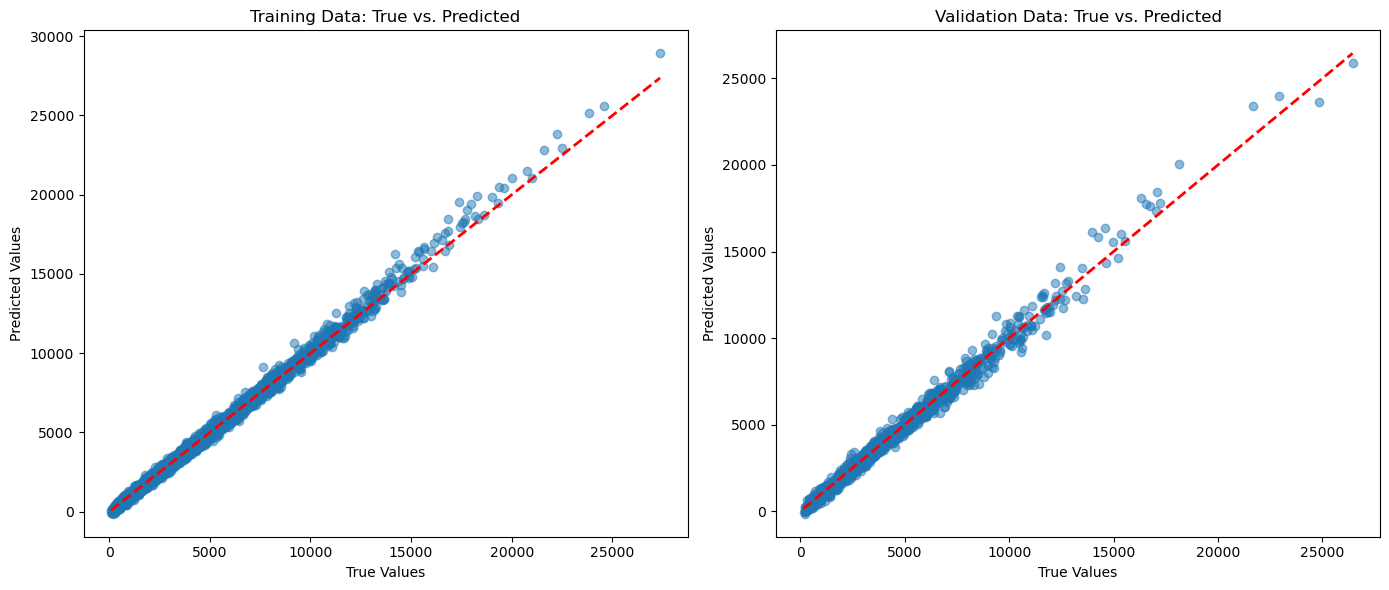


 Full Training Sample 

 Analysis Results (mean ± std over 3 seeds) 
Layers: 2 | Nodes: [64, 32] | Activation: relu | Epochs: 150 | Training samples: 7205
Training R^2: 0.9950 ± 0.0008 | Validation R^2: 0.9910 ± 0.0005


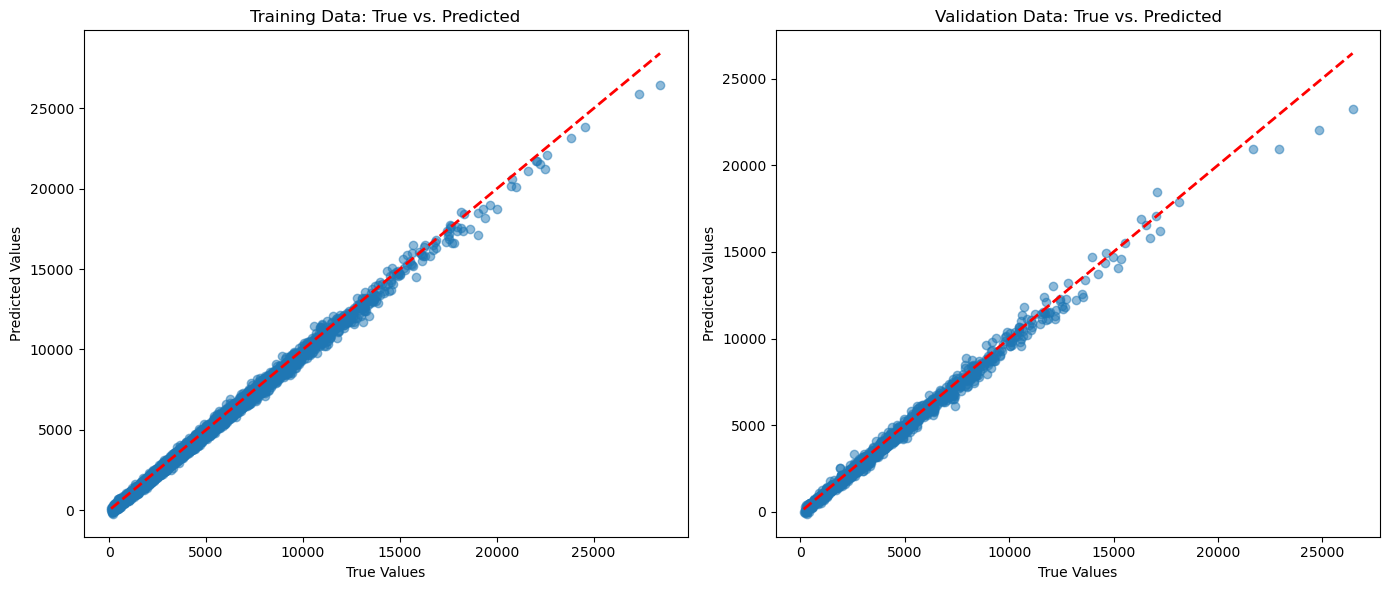

In [18]:
# Small sample (40% of the training data)
A_train_small, _, B_train_small, _ = train_test_split(A_train, B_train, train_size=0.4, random_state=42)
# Medium sample (70% of the training data)
A_train_medium, _, B_train_medium, _ = train_test_split(A_train, B_train, train_size=0.7, random_state=42)

print("Small Training Sample :",len(A_train_small))
print("Medium Training Sample:",len(A_train_medium))
print("Full Training Sample  :",len(A_train))

print("\nSmall Training Sample ")
S_pred = perform_analysis(A_train_small, B_train_small, A_val, B_val,
                          hidden_layers=[64, 32], activation_function='relu', epochs=150)

print("\n Medium Training Sample ")
M_pred = perform_analysis(A_train_medium, B_train_medium, A_val, B_val,
                          hidden_layers=[64, 32], activation_function='relu', epochs=150)

print("\n Full Training Sample ")
F_pred = perform_analysis(A_train, B_train, A_val, B_val,
                          hidden_layers=[64, 32], activation_function='relu', epochs=150)

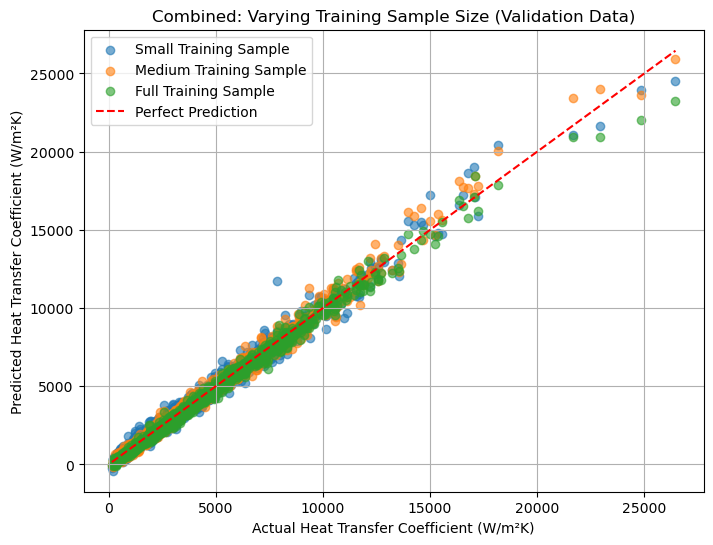

In [19]:
#Combined Plot

mplt.figure(figsize=(8,6))
mplt.scatter(B_val, S_pred, alpha=0.6, label='Small Training Sample')
mplt.scatter(B_val, M_pred, alpha=0.6, label='Medium Training Sample')
mplt.scatter(B_val, F_pred, alpha=0.6, label='Full Training Sample')

mplt.plot([B_val.min(), B_val.max()],
          [B_val.min(), B_val.max()],
          'r--', label="Perfect Prediction")

mplt.xlabel("Actual Heat Transfer Coefficient (W/m²K)")
mplt.ylabel("Predicted Heat Transfer Coefficient (W/m²K)")
mplt.title("Combined: Varying Training Sample Size (Validation Data)")
mplt.legend()
mplt.grid(True)
mplt.show()

## Summary of all the Analyses

In [20]:
#Summary table of all the configurations (mean and std of R^2 over the seeds)
summary=pa.DataFrame(results)
summary.round(4)

,Nodes,Activation,Epochs,Training samples,Evaluated on,Train R2 (mean),Train R2 (std),Eval R2 (mean),Eval R2 (std)
0,[64],relu,150,7205,Validation,0.9928,0.0013,0.9903,0.0019
1,"[64, 32]",relu,150,7205,Validation,0.9950,0.0008,0.9910,0.0005
2,"[64, 32, 16]",relu,150,7205,Validation,0.9952,0.0007,0.9906,0.0008
3,"[16, 8]",relu,150,7205,Validation,0.9888,0.0020,0.9860,0.0019
4,"[64, 32]",relu,150,7205,Validation,0.9950,0.0008,0.9910,0.0005
5,"[128, 64]",relu,150,7205,Validation,0.9947,0.0018,0.9899,0.0016
6,"[64, 32]",tanh,150,7205,Validation,0.9947,0.0004,0.9936,0.0002
7,"[64, 32]",relu,150,7205,Validation,0.9950,0.0008,0.9910,0.0005
8,"[64, 32]",sigmoid,150,7205,Validation,0.9885,0.0048,0.9878,0.0048
9,"[64, 32]",relu,50,7205,Validation,0.9917,0.0019,0.9872,0.0020


## Final Model on the Test Data
The configuration with the highest mean validation R² is **2 hidden layers [64, 32] with tanh activation and 150 epochs**.
It is trained again on the full training data (3 seeds) and evaluated once on the test data, which was not used in any of the comparisons above.



 Final Model: Nodes = [64, 32], Activation = tanh, Epochs = 150 

 Analysis Results (mean ± std over 3 seeds) 
Layers: 2 | Nodes: [64, 32] | Activation: tanh | Epochs: 150 | Training samples: 7205
Training R^2: 0.9947 ± 0.0004 | Test R^2: 0.9935 ± 0.0004


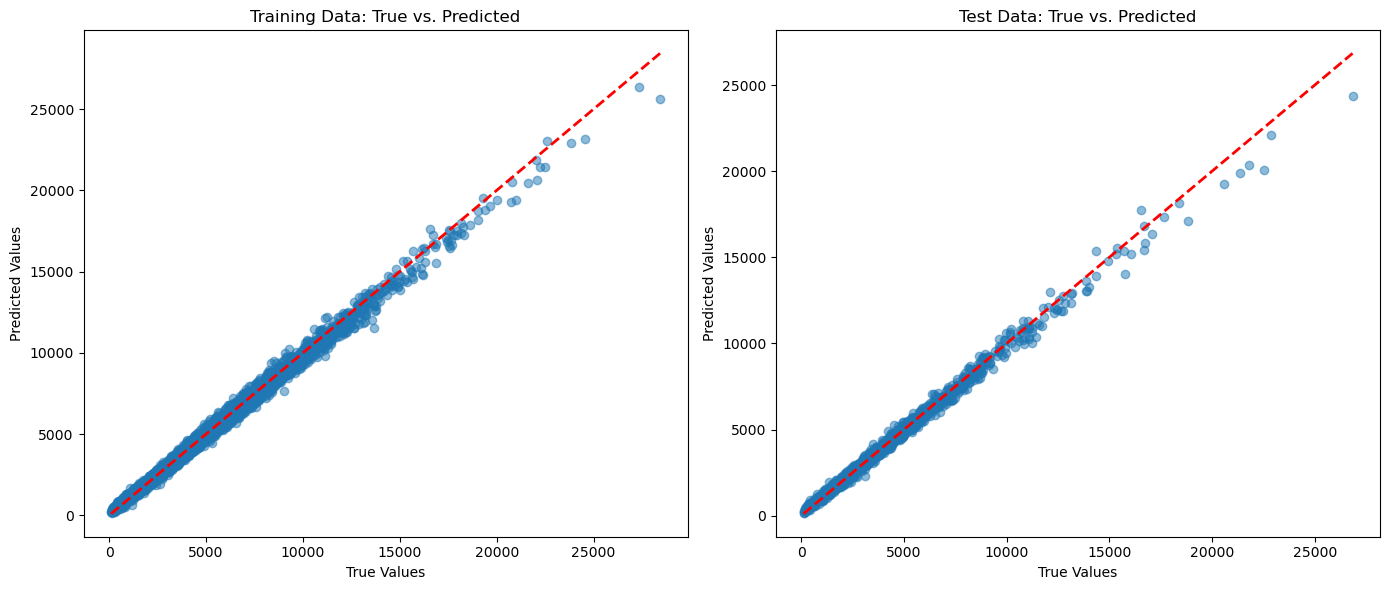

In [21]:
print("\n\n Final Model: Nodes = [64, 32], Activation = tanh, Epochs = 150 ")
Final_pred = perform_analysis(A_train, B_train, A_test, B_test,
                              hidden_layers=[64, 32], activation_function='tanh', epochs=150,
                              eval_name='Test')